# Data Preparation - BIODIVERSITY-GUARD-Predict
## Hito 3: preparación de datos sobre el panel semanal

**Entrada única:** `datos/datasets_eda/dataset_panel_semanal_COMPLETO.csv` (136,293 filas x 31 columnas; 543 municipios x 251 semanas, de lunes 2022-01-03 a lunes 2026-10-19). La clave es `(municipio_norm, uf, semana)`.

**Salidas** (carpeta `datos/datasets_preparation/`): `dataset_panel_PREPARADO.csv`, `parametros_preparacion.json`, `lista_features.json` y `kpi_parametros.json`. Los archivos `dataset_alertas_PREPARADO.csv` y `dataset_semanal_PREPARADO.csv` son del Hito 2 y no se usan ni se modifican.

### Definición del problema
- **Frente 1 (regresión):** `y_7d` es el número de focos (`num_incendios`) de la semana siguiente e `y_30d` es la suma de las 4 semanas siguientes. El panel es completo, con ceros.
- **Frente 2 (clasificación):** `clase_t1` es la clase de riesgo de fuego de la semana siguiente (solo `t+1`), a partir de `riesgo_fuego_promedio` con cortes 0.40 / 0.70 / 0.95: **Bajo** (hasta 0.40), **Moderado** (0.40 a 0.70], **Alto** (0.70 a 0.95] y **Crítico** (más de 0.95). Se codifica como ordinal de 0 a 3. Solo existe donde la semana siguiente tiene riesgo calculado.
- DETER **no** es target ni predictora: solo contexto para el KPI.

### Particiones
| Partición | Semanas (lunes) | Uso |
|---|---|---|
| Descartada (inicio) | 2022-01-03 a 2022-01-24 | Sin los 4 rezagos completos |
| Entrenamiento | 2022-01-31 a 2024-12-02 | Ajusta todos los parámetros; validación cruzada temporal |
| Margen | 2024-12-09 a 2024-12-30 | 4 semanas que no entran en ninguna partición (la ventana de `y_30d` termina el 2024-12-30) |
| Prueba final | 2025-01-06 a 2025-12-22 | Evaluación final, 2025 |
| Descartada (cambio de fuente) | 2025-12-29 | Mezcla reanálisis y pronóstico de SISAM |
| Flujo simulado 2026 | 2026-01-05 a 2026-10-19 | No entrena ni se usa para elegir nada |

**Validación cruzada temporal** (ventana expansiva, margen de 4 semanas): 4 pliegos con validación en 2023 S1 (enero a junio), 2023 S2 (julio a diciembre), 2024 S1 y 2024 S2. Cada pliego entrena con todo lo anterior a su inicio menos 4 semanas de margen.

### Regla anti fuga
Todo parámetro que se **ajusta** (límites de atípicos, lista de variables con `log1p`, medias y desviaciones del `StandardScaler`, medianas de imputación, percentiles de KPI y VIF) se calcula **solo con las filas de entrenamiento** y después se **aplica** igual a prueba y a 2026. Los rezagos y los promedios móviles usan solo semanas anteriores o iguales a `t`.

**Limitación:** estos parámetros se ajustan con todo el entrenamiento y no pliego por pliego. Los modelos de árboles no se afectan por el escalado.


## Índice de figuras

| Figura | Título | Sección |
|---|---|---|
| 1 | Particiones, margen y pliegos de validación cruzada temporal (2022 a 2026) | 1. Data Collecting |
| 2 | Valores atípicos antes y después del tratamiento por variable, entrenamiento 2022 a 2024 | 2. Data Cleaning |
| 3 | Factor de inflación de la varianza (VIF) final de las predictoras continuas, entrenamiento | 4. Data Reduction |


## Configuración del entorno


In [1]:
from pathlib import Path
import unicodedata

import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# 1. Entorno: Google Colab (Drive) o ejecucion local
# ---------------------------------------------------------------------------
USAR_DRIVE = True   # True en Colab; False para trabajar con la carpeta local del repositorio
BASE_DRIVE = Path("/content/drive/MyDrive/BIODIVERSITY_GUARD")

if USAR_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        BASE = BASE_DRIVE
    except ImportError:
        print("No se detecto Google Colab: se usa la raiz local del repositorio.")
        USAR_DRIVE = False

if not USAR_DRIVE:
    # la raiz es la primera carpeta (hacia arriba desde la actual) que contiene "datos"
    _aqui = Path.cwd().resolve()
    BASE = next((p for p in [_aqui, *_aqui.parents] if (p / "datos").is_dir()), None)
    if BASE is None:
        raise FileNotFoundError("No se encontro la carpeta 'datos' subiendo desde " + str(_aqui))

if not BASE.exists():
    raise FileNotFoundError(f"No existe BASE = {BASE}. Verifica la carpeta BIODIVERSITY_GUARD en Drive.")

# ---------------------------------------------------------------------------
# 2. Rutas (todas salen de BASE)
# ---------------------------------------------------------------------------
DIR_PREP = BASE / "datos" / "datasets_preprocesamiento"
DIR_BDQ = DIR_PREP / "BDQueimadas"
DIR_DETER = DIR_PREP / "DETER"
DIR_NASA = DIR_PREP / "NasaPower"
DIR_SISAM = DIR_PREP / "SISAM"
DIR_EDA = BASE / "datos" / "datasets_eda"

# ---------------------------------------------------------------------------
# 3. Constantes comunes (identicas en los 7 notebooks)
# ---------------------------------------------------------------------------
FECHA_INICIO_DATOS = "2022-01-01"
FECHA_FIN_EXTRACCION = "2026-11-01"      # DETER y BDQueimadas
PRIMERA_SEMANA = "2022-01-03"             # primer lunes con semana completa (2022-01-01 es sabado)
ULTIMA_SEMANA = "2026-10-19"              # lunes de la ultima semana completa (termina domingo 2026-10-25)
SATELITE_REFERENCIA = "AQUA_M-T"
ESTADOS_AMAZONIA_LEGAL = ["ACRE", "AMAPÁ", "AMAZONAS", "MARANHÃO", "MATO GROSSO", "PARÁ", "RONDÔNIA", "RORAIMA", "TOCANTINS"]
MAPA_UF = {"ACRE": "AC", "AMAPÁ": "AP", "AMAZONAS": "AM", "MARANHÃO": "MA", "MATO GROSSO": "MT", "PARÁ": "PA", "RONDÔNIA": "RO", "RORAIMA": "RR", "TOCANTINS": "TO"}
CORRECCIONES_MUNICIPIO = {"ELDORADO DOS CARAJAS": "ELDORADO DO CARAJAS", "SANTA ISABEL DO PARA": "SANTA IZABEL DO PARA"}
FECHA_CORTE_CENTROIDES = "2024-12-31"     # los centroides se fijan con focos hasta esta fecha

# ---------------------------------------------------------------------------
# 4. Funciones comunes
# ---------------------------------------------------------------------------
def normalizar_texto(texto):
    # mayusculas, sin tildes ni espacios sobrantes
    if pd.isna(texto):
        return texto
    texto = str(texto).upper().strip()
    return unicodedata.normalize("NFKD", texto).encode("ASCII", "ignore").decode("utf-8")


def semana_lunes(fecha):
    # lunes de la semana (lunes a domingo) de cada fecha; recibe una Serie de fechas
    f = pd.to_datetime(fecha).dt.normalize()
    return f - pd.to_timedelta(f.dt.day_of_week, unit="D")


SEMANAS = pd.date_range(PRIMERA_SEMANA, ULTIMA_SEMANA, freq="W-MON")   # calendario de semanas completas
assert len(SEMANAS) == 251, f"El calendario deberia tener 251 semanas y tiene {len(SEMANAS)}"
assert (SEMANAS.day_of_week == 0).all(), "Todas las semanas deben empezar en lunes"


def verificar_entradas(archivos):
    # imprime los archivos de entrada con su tamano y falla si falta alguno
    faltan = []
    for a in map(Path, archivos):
        if a.exists():
            print(f"  OK  {a.relative_to(BASE)}  ({a.stat().st_size / 1e6:,.1f} MB)")
        else:
            faltan.append(a)
    if faltan:
        lista = "\n".join(f"  - {a}" for a in faltan)
        raise FileNotFoundError("Faltan archivos de entrada (copialos a esas carpetas y vuelve a ejecutar):\n" + lista)


print("BASE:", BASE)
print("Calendario:", SEMANAS[0].date(), "a", SEMANAS[-1].date(), f"({len(SEMANAS)} semanas)")


No se detecto Google Colab: se usa la raiz local del repositorio.
BASE: C:\UPC-DOCS\CICLO7\MACHINE LEARNING\HITO3\BIODIVERSITY_GUARD
Calendario: 2022-01-03 a 2026-10-19 (251 semanas)


In [2]:
import json
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 70
pd.set_option("display.max_columns", None)

ALEATORIO = 42
CLAVE = ["municipio_norm", "uf"]
DIR_PREPARATION = BASE / "datos" / "datasets_preparation"
DIR_PREPARATION.mkdir(parents=True, exist_ok=True)
PARAMS = {}   # parametros que se guardan en parametros_preparacion.json


def mostrar(tabla, decimales=2):
    # imprime una tabla con miles separados por coma y decimales controlados
    print(tabla.to_string(float_format=lambda v: f"{v:,.{decimales}f}"))


## 1. Data Collecting

### 1.1 Carga del panel
Se carga el panel y se verifica su integridad: forma, número de municipios y semanas, ausencia de claves duplicadas y semanas completas y consecutivas por municipio.


In [3]:
RUTA_PANEL = DIR_EDA / "dataset_panel_semanal_COMPLETO.csv"
verificar_entradas([RUTA_PANEL])

df = pd.read_csv(RUTA_PANEL, parse_dates=["semana"])
assert df.shape == (136293, 31), f"Forma inesperada: {df.shape}"
df = df.sort_values(CLAVE + ["semana"]).reset_index(drop=True)

assert df[CLAVE].drop_duplicates().shape[0] == 543, "Debe haber 543 municipios (municipio_norm, uf)"
assert df["semana"].nunique() == 251, "Debe haber 251 semanas"
assert pd.DatetimeIndex(sorted(df["semana"].unique())).equals(SEMANAS), "Las semanas no coinciden con el calendario"
assert not df.duplicated(CLAVE + ["semana"]).any(), "Hay claves duplicadas"
assert (df.groupby(CLAVE).size() == 251).all(), "Hay municipios con semanas faltantes"
assert (df["semana"].dt.day_of_week == 0).all(), "Todas las semanas deben empezar en lunes"
assert (df.groupby(CLAVE)["semana"].diff().dropna() == pd.Timedelta(days=7)).all(), "Semanas no consecutivas"

df["anio"] = df["semana"].dt.year
print("Forma:", df.shape, "| municipios:", df[CLAVE].drop_duplicates().shape[0], "| semanas:", df["semana"].nunique())
print("Rango:", df["semana"].min().date(), "a", df["semana"].max().date())
print("Controles de integridad: OK")


  OK  datos\datasets_eda\dataset_panel_semanal_COMPLETO.csv  (40.8 MB)
Forma: (136293, 32) | municipios: 543 | semanas: 251
Rango: 2022-01-03 a 2026-10-19
Controles de integridad: OK


### 1.2 Particiones y pliegos de validación cruzada temporal
Las particiones se definen solo por fecha. El margen de 4 semanas separa el entrenamiento de la prueba, y cada pliego deja 4 semanas entre su entrenamiento y su validación. La función `pliegos_temporales()` devuelve los índices de cada pliego y verifica con un `assert` que no haya solapamiento.


In [4]:
ENT_INI, ENT_FIN = pd.Timestamp("2022-01-31"), pd.Timestamp("2024-12-02")
MARGEN_INI, MARGEN_FIN = pd.Timestamp("2024-12-09"), pd.Timestamp("2024-12-30")
PRUEBA_INI, PRUEBA_FIN = pd.Timestamp("2025-01-06"), pd.Timestamp("2025-12-22")
FLUJO_INI, FLUJO_FIN = pd.Timestamp("2026-01-05"), pd.Timestamp("2026-10-19")
SEMANA_CAMBIO_FUENTE = pd.Timestamp("2025-12-29")
SEMANAS_MARGEN = 4

assert MARGEN_INI - ENT_FIN == pd.Timedelta(weeks=1) and MARGEN_FIN - MARGEN_INI == pd.Timedelta(weeks=SEMANAS_MARGEN - 1)
assert PRUEBA_INI - ENT_FIN == pd.Timedelta(weeks=SEMANAS_MARGEN + 1), "Entre el entrenamiento y la prueba debe haber 4 semanas de margen"
assert FLUJO_INI - SEMANA_CAMBIO_FUENTE == pd.Timedelta(weeks=1)


def asignar_particion(semana):
    # partición de cada semana (Serie de fechas) según las reglas del Hito 3
    return np.select(
        [(semana >= ENT_INI) & (semana <= ENT_FIN),
         (semana >= MARGEN_INI) & (semana <= MARGEN_FIN),
         (semana >= PRUEBA_INI) & (semana <= PRUEBA_FIN),
         (semana >= FLUJO_INI) & (semana <= FLUJO_FIN)],
        ["entrenamiento", "margen", "prueba", "flujo_2026"], default="descartada")


df["particion"] = asignar_particion(df["semana"])

resumen_particion = df.groupby("particion").agg(
    semanas=("semana", "nunique"), desde=("semana", "min"), hasta=("semana", "max"), filas=("semana", "size"))
print("Particiones del panel:")
print(resumen_particion.loc[["entrenamiento", "margen", "prueba", "flujo_2026", "descartada"]].to_string())
print("\nSemanas descartadas:", [d.date().isoformat() for d in sorted(df.loc[df["particion"] == "descartada", "semana"].unique())])


Particiones del panel:
               semanas      desde      hasta  filas
particion                                          
entrenamiento      149 2022-01-31 2024-12-02  80907
margen               4 2024-12-09 2024-12-30   2172
prueba              51 2025-01-06 2025-12-22  27693
flujo_2026          42 2026-01-05 2026-10-19  22806
descartada           5 2022-01-03 2025-12-29   2715

Semanas descartadas: ['2022-01-03', '2022-01-10', '2022-01-17', '2022-01-24', '2025-12-29']


In [5]:
VENTANAS_VALIDACION = [("2023-01-02", "2023-06-26"), ("2023-07-03", "2023-12-25"),
                       ("2024-01-01", "2024-06-24"), ("2024-07-01", "2024-12-02")]


def pliegos_temporales(panel):
    # 4 pliegos de ventana expansiva; el entrenamiento termina 5 semanas antes del inicio de la validacion
    # (4 semanas de margen). Devuelve indices del panel y las fechas de cada pliego.
    es_ent = panel["particion"].eq("entrenamiento")
    pliegos = []
    for numero, (inicio, fin) in enumerate(VENTANAS_VALIDACION, start=1):
        inicio, fin = pd.Timestamp(inicio), pd.Timestamp(fin)
        fin_entreno = inicio - pd.Timedelta(weeks=SEMANAS_MARGEN + 1)
        idx_entreno = panel.index[es_ent & (panel["semana"] <= fin_entreno)]
        idx_valid = panel.index[es_ent & panel["semana"].between(inicio, fin)]
        max_entreno = panel.loc[idx_entreno, "semana"].max()
        min_valid = panel.loc[idx_valid, "semana"].min()
        assert max_entreno + pd.Timedelta(weeks=SEMANAS_MARGEN) < min_valid, f"Pliego {numero}: falta el margen de 4 semanas"
        pliegos.append({"pliego": numero, "idx_entreno": idx_entreno, "idx_validacion": idx_valid,
                        "entreno_ini": panel.loc[idx_entreno, "semana"].min(), "entreno_fin": max_entreno,
                        "valid_ini": min_valid, "valid_fin": panel.loc[idx_valid, "semana"].max()})
    return pliegos


PLIEGOS = pliegos_temporales(df)
df["pliego_validacion"] = pd.array([pd.NA] * len(df), dtype="Int8")
for p in PLIEGOS:
    df.loc[p["idx_validacion"], "pliego_validacion"] = p["pliego"]

tabla_pliegos = pd.DataFrame([{
    "pliego": p["pliego"], "entreno_desde": p["entreno_ini"].date(), "entreno_hasta": p["entreno_fin"].date(),
    "validacion_desde": p["valid_ini"].date(), "validacion_hasta": p["valid_fin"].date(),
    "semanas_entreno": df.loc[p["idx_entreno"], "semana"].nunique(), "semanas_validacion": df.loc[p["idx_validacion"], "semana"].nunique(),
    "filas_entreno": len(p["idx_entreno"]), "filas_validacion": len(p["idx_validacion"])} for p in PLIEGOS]).set_index("pliego")
print("Pliegos de validación cruzada temporal (verificado: máximo del entrenamiento + 4 semanas < inicio de la validación):")
print(tabla_pliegos.to_string())

PARAMS["particiones"] = {
    "entrenamiento": [ENT_INI.date().isoformat(), ENT_FIN.date().isoformat()],
    "margen": [MARGEN_INI.date().isoformat(), MARGEN_FIN.date().isoformat()],
    "prueba": [PRUEBA_INI.date().isoformat(), PRUEBA_FIN.date().isoformat()],
    "flujo_2026": [FLUJO_INI.date().isoformat(), FLUJO_FIN.date().isoformat()],
    "descartadas": [d.date().isoformat() for d in sorted(df.loc[df["particion"] == "descartada", "semana"].unique())],
    "semanas_de_margen": SEMANAS_MARGEN}
PARAMS["pliegos"] = [{"pliego": p["pliego"], "entreno": [p["entreno_ini"].date().isoformat(), p["entreno_fin"].date().isoformat()],
                      "validacion": [p["valid_ini"].date().isoformat(), p["valid_fin"].date().isoformat()]} for p in PLIEGOS]


Pliegos de validación cruzada temporal (verificado: máximo del entrenamiento + 4 semanas < inicio de la validación):
       entreno_desde entreno_hasta validacion_desde validacion_hasta  semanas_entreno  semanas_validacion  filas_entreno  filas_validacion
pliego                                                                                                                                    
1         2022-01-31    2022-11-28       2023-01-02       2023-06-26               44                  26          23892             14118
2         2022-01-31    2023-05-29       2023-07-03       2023-12-25               70                  26          38010             14118
3         2022-01-31    2023-11-27       2024-01-01       2024-06-24               96                  26          52128             14118
4         2022-01-31    2024-05-27       2024-07-01       2024-12-02              122                  23          66246             12489


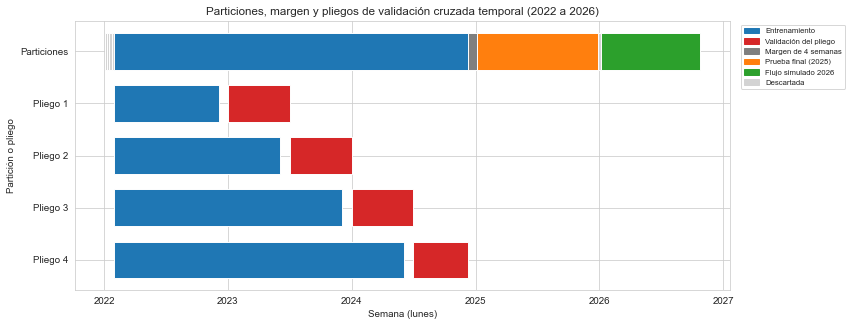

In [6]:
fig, ax = plt.subplots(figsize=(13, 5))
COLORES_PARTICION = {"entrenamiento": "tab:blue", "margen": "tab:gray", "prueba": "tab:orange", "flujo_2026": "tab:green", "descartada": "lightgray"}


def barra(eje, y, inicio, fin, color):
    # barra horizontal entre dos lunes (incluye la semana final)
    ancho = (pd.Timestamp(fin) - pd.Timestamp(inicio)).days + 7
    eje.broken_barh([(mdates.date2num(pd.Timestamp(inicio)), ancho)], (y - 0.35, 0.7), facecolors=color)


for nombre, grupo in df.groupby("particion"):
    # un tramo continuo por partición (las descartadas se dibujan semana a semana)
    for semana in (sorted(grupo["semana"].unique()) if nombre == "descartada" else [grupo["semana"].min()]):
        fin = semana if nombre == "descartada" else grupo["semana"].max()
        barra(ax, 0, semana, fin, COLORES_PARTICION[nombre])
for p in PLIEGOS:
    barra(ax, p["pliego"], p["entreno_ini"], p["entreno_fin"], "tab:blue")
    barra(ax, p["pliego"], p["valid_ini"], p["valid_fin"], "tab:red")
ax.xaxis_date()
ax.set_yticks(range(0, 5))
ax.set_yticklabels(["Particiones", "Pliego 1", "Pliego 2", "Pliego 3", "Pliego 4"])
ax.invert_yaxis()
ax.set_xlabel("Semana (lunes)")
ax.set_ylabel("Partición o pliego")
ax.set_title("Particiones, margen y pliegos de validación cruzada temporal (2022 a 2026)")
ax.legend(handles=[Patch(color=COLORES_PARTICION["entrenamiento"], label="Entrenamiento"),
                   Patch(color="tab:red", label="Validación del pliego"),
                   Patch(color=COLORES_PARTICION["margen"], label="Margen de 4 semanas"),
                   Patch(color=COLORES_PARTICION["prueba"], label="Prueba final (2025)"),
                   Patch(color=COLORES_PARTICION["flujo_2026"], label="Flujo simulado 2026"),
                   Patch(color=COLORES_PARTICION["descartada"], label="Descartada")],
          loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
fig.subplots_adjust(left=0.08, right=0.80)
plt.show()


**Figura 1.** Línea de tiempo de las particiones (entrenamiento, margen de 4 semanas, prueba final, flujo simulado 2026 y semanas descartadas) y de los cuatro pliegos de validación cruzada temporal. Usa todas las semanas del panel.


### 1.3 Construcción de variables (solo pasado)
Todo se calcula con `groupby([municipio_norm, uf])` sobre el panel ordenado y completo:
- **Targets:** `y_7d`, `y_30d` (suma de las 4 semanas siguientes, con `min_count=4`) y sus versiones `log1p`; `clase_t1` (con su codificación ordinal) y `clase_t` (clase de la semana actual, para el baseline de persistencia).
- **Rezagos y rodantes de focos:** `num_incendios` con rezagos de 1 a 4 semanas y media móvil de 4 semanas (`num_incendios_mm4`, incluye la semana `t`).
- **Rezagos de NASA POWER** de 1 a 4 semanas para `precip_acum_30d`, `dias_sin_lluvia_nasa`, `RH2M`, `T2M_MAX`, `T2M` y `precip_nasa_sem`.
- **Frente 2:** `riesgo_fuego_t` (riesgo de la semana actual) y la bandera `sin_riesgo_t`.
- **Calendario y ubicación:** `temporada_seca` (julio a noviembre), `sem_anio_sin` y `sem_anio_cos` (periodo de 52 semanas), `lat` y `lon`.
- Se conservan copias sin transformar para el KPI y el dashboard (`num_incendios_crudo`, `lat_grados`, `lon_grados`, `ctx_pm2_5_reanalise` y `ctx_pm10_reanalise`).


In [7]:
CORTES_RIESGO = [-np.inf, 0.40, 0.70, 0.95, np.inf]
CLASES = ["Bajo", "Moderado", "Alto", "Crítico"]
ORDINAL_CLASE = {c: i for i, c in enumerate(CLASES)}
COLS_NASA_ACTUAL = ["T2M", "T2M_MAX", "RH2M", "WS2M", "precip_nasa_sem", "dias_sin_lluvia_nasa", "precip_acum_30d", "precip_acum_120d"]
COLS_SISAM = ["pm10_reanalise", "pm2_5_reanalise", "o3_reanalise", "no2_reanalise", "co_reanalise", "so2_reanalise"]
VARS_REZAGO_NASA = ["precip_acum_30d", "dias_sin_lluvia_nasa", "RH2M", "T2M_MAX", "T2M", "precip_nasa_sem"]
REZAGOS = [1, 2, 3, 4]
COLS_REZ_FOCOS = [f"num_incendios_rez{k}" for k in REZAGOS]
COLS_REZ_NASA = [f"{v}_rez{k}" for v in VARS_REZAGO_NASA for k in REZAGOS]


def construir_variables(panel):
    # targets, rezagos y variables de calendario; solo usa semanas anteriores o iguales a t (los targets miran al futuro por definicion)
    panel = panel.sort_values(CLAVE + ["semana"]).reset_index(drop=True)
    g = panel.groupby(CLAVE)
    focos = g["num_incendios"]
    nuevas = {}

    nuevas["y_7d"] = focos.shift(-1)
    siguientes = pd.concat([focos.shift(-k) for k in range(1, 5)], axis=1)
    nuevas["y_30d"] = siguientes.sum(axis=1, min_count=4)
    nuevas["y_7d_log"] = np.log1p(nuevas["y_7d"])
    nuevas["y_30d_log"] = np.log1p(nuevas["y_30d"])

    clase_t = pd.cut(panel["riesgo_fuego_promedio"], CORTES_RIESGO, labels=CLASES).astype(object)
    clase_t1 = pd.cut(g["riesgo_fuego_promedio"].shift(-1), CORTES_RIESGO, labels=CLASES).astype(object)
    nuevas["clase_t"] = clase_t
    nuevas["clase_t1"] = clase_t1
    nuevas["clase_t1_ord"] = clase_t1.map(ORDINAL_CLASE).astype("Int8")

    for k in REZAGOS:
        nuevas[f"num_incendios_rez{k}"] = focos.shift(k)
    nuevas["num_incendios_mm4"] = focos.transform(lambda s: s.rolling(4).mean())
    for variable in VARS_REZAGO_NASA:
        for k in REZAGOS:
            nuevas[f"{variable}_rez{k}"] = g[variable].shift(k)

    nuevas["riesgo_fuego_t"] = panel["riesgo_fuego_promedio"]
    nuevas["sin_riesgo_t"] = panel["riesgo_fuego_promedio"].isna().astype("int8")

    mes = panel["semana"].dt.month
    sem_anio = (panel["semana"].dt.day_of_year - 1) // 7 + 1
    nuevas["temporada_seca"] = mes.between(7, 11).astype("int8")
    nuevas["sem_anio_sin"] = np.sin(2 * np.pi * sem_anio / 52)
    nuevas["sem_anio_cos"] = np.cos(2 * np.pi * sem_anio / 52)

    nuevas["num_incendios_crudo"] = panel["num_incendios"]
    nuevas["lat_grados"] = panel["lat"]
    nuevas["lon_grados"] = panel["lon"]
    nuevas["ctx_pm2_5_reanalise"] = panel["pm2_5_reanalise"]
    nuevas["ctx_pm10_reanalise"] = panel["pm10_reanalise"]
    return pd.concat([panel, pd.DataFrame(nuevas, index=panel.index)], axis=1)


columnas_panel = list(df.columns)
df = construir_variables(df)
COLS_NUEVAS = [c for c in df.columns if c not in columnas_panel]
print("Forma tras construir variables:", df.shape, "| columnas nuevas:", len(COLS_NUEVAS))
print(sorted(COLS_NUEVAS)[:12], "...")


Forma tras construir variables: (136293, 80) | columnas nuevas: 46
['RH2M_rez1', 'RH2M_rez2', 'RH2M_rez3', 'RH2M_rez4', 'T2M_MAX_rez1', 'T2M_MAX_rez2', 'T2M_MAX_rez3', 'T2M_MAX_rez4', 'T2M_rez1', 'T2M_rez2', 'T2M_rez3', 'T2M_rez4'] ...


In [8]:
def verificar_a_mano(panel, n_municipios=3):
    # recalcula a mano rezagos, media movil y targets para n municipios y los compara con las columnas construidas
    muestra = panel[CLAVE].drop_duplicates().sample(n_municipios, random_state=ALEATORIO)
    for _, fila in muestra.iterrows():
        s = panel[(panel["municipio_norm"] == fila["municipio_norm"]) & (panel["uf"] == fila["uf"])].sort_values("semana")
        x = s["num_incendios"].to_numpy(float)
        for k in REZAGOS:
            esperado = np.r_[np.full(k, np.nan), x[:-k]]
            assert np.allclose(s[f"num_incendios_rez{k}"].to_numpy(float), esperado, equal_nan=True), f"Rezago {k} de focos incorrecto"
        mm4 = np.r_[np.full(3, np.nan), [x[i - 3:i + 1].mean() for i in range(3, len(x))]]
        assert np.allclose(s["num_incendios_mm4"].to_numpy(float), mm4, equal_nan=True), "Media móvil incorrecta"
        assert np.allclose(s["y_7d"].to_numpy(float), np.r_[x[1:], np.nan], equal_nan=True), "y_7d incorrecto"
        y30 = np.r_[[x[i + 1:i + 5].sum() for i in range(len(x) - 4)], np.full(4, np.nan)]
        assert np.allclose(s["y_30d"].to_numpy(float), y30, equal_nan=True), "y_30d incorrecto"
        for variable in VARS_REZAGO_NASA:
            v = s[variable].to_numpy(float)
            for k in REZAGOS:
                assert np.allclose(s[f"{variable}_rez{k}"].to_numpy(float), np.r_[np.full(k, np.nan), v[:-k]], equal_nan=True), f"Rezago {k} de {variable} incorrecto"
    return list(map(tuple, muestra[CLAVE].to_numpy()))


municipios_prueba = verificar_a_mano(df)
print("Verificación a mano (rezagos, media móvil y targets) correcta para:", municipios_prueba)


Verificación a mano (rezagos, media móvil y targets) correcta para: [('VILA NOVA DOS MARTIRIOS', 'MA'), ('SAO VICENTE FERRER', 'MA'), ("PAU D'ARCO", 'PA')]


### 1.4 Nivel de focos para el KPI
Los cortes del KPI son los percentiles 50 y 75 de `num_incendios` por temporada (seca = julio a noviembre), **entre las semanas con focos del entrenamiento**. El nivel es Sin focos, Habitual (hasta el p50), Elevado (hasta el p75) o Muy elevado (más del p75). **La alerta es el nivel Muy elevado.**


In [9]:
es_ent = df["particion"].eq("entrenamiento")
con_focos_ent = df[es_ent & (df["num_incendios"] > 0)]
cortes_kpi = con_focos_ent.groupby("temporada_seca")["num_incendios"].quantile([0.5, 0.75]).unstack()
cortes_kpi.columns = ["p50", "p75"]
cortes_kpi.index = ["humeda" if i == 0 else "seca" for i in cortes_kpi.index]
print(f"Cortes del KPI (semanas con focos del entrenamiento, {len(con_focos_ent):,} semanas-municipio):")
mostrar(cortes_kpi, 1)

p50 = np.where(df["temporada_seca"] == 1, cortes_kpi.loc["seca", "p50"], cortes_kpi.loc["humeda", "p50"])
p75 = np.where(df["temporada_seca"] == 1, cortes_kpi.loc["seca", "p75"], cortes_kpi.loc["humeda", "p75"])
df["nivel_focos"] = np.select(
    [df["num_incendios"] == 0, df["num_incendios"] <= p50, df["num_incendios"] <= p75],
    ["Sin focos", "Habitual", "Elevado"], default="Muy elevado")
PARAMS["kpi_cortes_focos"] = {t: {"p50": float(cortes_kpi.loc[t, "p50"]), "p75": float(cortes_kpi.loc[t, "p75"])} for t in cortes_kpi.index}

niveles = pd.crosstab(df["particion"], df["nivel_focos"])[["Sin focos", "Habitual", "Elevado", "Muy elevado"]]
print("\nNivel de focos por partición (filas):")
print(niveles.loc[["entrenamiento", "prueba", "flujo_2026"]].to_string())


Cortes del KPI (semanas con focos del entrenamiento, 26,133 semanas-municipio):
        p50  p75
humeda  2.0  5.0
seca    4.0 12.0

Nivel de focos por partición (filas):
nivel_focos    Sin focos  Habitual  Elevado  Muy elevado
particion                                               
entrenamiento      54774     14062     6097         5974
prueba             20923      4067     1590         1113
flujo_2026         17808      2958     1099          941


### Hallazgos de esta etapa

**Qué se observa**
- El panel pasó todos los controles de integridad: **136,293 filas x 31 columnas**, **543 municipios**, **251 semanas**, sin claves duplicadas.
- Particiones (ver Figura 1): entrenamiento **149 semanas** (**80,907** filas, del 2022-01-31 al 2024-12-02), margen **4 semanas** (**2,172** filas), prueba **51 semanas** (**27,693**), flujo 2026 **42 semanas** (**22,806**) y **5** semanas descartadas (las 4 primeras y 2025-12-29).
- Los 4 pliegos entrenan con **44**, **70**, **96** y **122** semanas y validan con **26**, **26**, **26** y **23** semanas. En todos se cumple que el máximo del entrenamiento más 4 semanas es menor que el inicio de la validación.
- Los rezagos, la media móvil y los targets coinciden con el cálculo a mano en 3 municipios. Los cortes del KPI salen de **26,133** semanas-municipio con focos: **2.0** y **5.0** (húmeda) y **4.0** y **12.0** (seca), iguales a los del EDA. El nivel Muy elevado (la alerta) tiene **5,974** filas en entrenamiento, **1,113** en prueba y **941** en 2026.

**Por qué se decidió así**
- Las 4 primeras semanas quedan fuera del entrenamiento porque no tienen los 4 rezagos completos (**2,172** nulos en 2022, es decir 4 semanas x 543 municipios).
- El margen de 4 semanas evita que la ventana de `y_30d` de las últimas semanas de entrenamiento entre en la prueba.
- Los cortes del KPI se calculan solo con el entrenamiento, para no usar información de 2025 ni de 2026.

**Qué implica para el modelado**
- **Limitación:** el pliego 1 entrena con solo **44** semanas, menos de un ciclo anual completo, así que sus métricas son menos estables que las de los otros pliegos.
- **Limitación:** los parámetros se ajustan con todo el entrenamiento y no pliego por pliego. Los modelos de árboles no se afectan por el escalado.


## 2. Data Cleaning

### 2.1 Valores faltantes
Reglas del EDA:
- Los nulos de las columnas de BDQueimadas (`frp_promedio`, `precipitacion_promedio`, `dias_sin_lluvia_promedio`, `riesgo_fuego_promedio` y `riesgo_fuego_max`) son **estructurales** (semanas sin focos). **No se imputan y esas columnas no son predictoras.** Solo entra `riesgo_fuego_t` para el Frente 2: su nulo se imputa con la **mediana del entrenamiento**, y la bandera `sin_riesgo_t` conserva el dato original.
- Las filas sin rezagos completos o sin target (primeras y últimas semanas) **no se borran**: se marcan con `valido_f1` y `valido_f2`. `valido_f1` exige rezagos completos y `y_7d`; `valido_f1_30d` exige además `y_30d`; `valido_f2` exige `clase_t1` no nula.


In [10]:
COLS_VER_NULOS = ["frp_promedio", "precipitacion_promedio", "dias_sin_lluvia_promedio", "riesgo_fuego_promedio", "riesgo_fuego_max",
                  "riesgo_fuego_t", "num_incendios_rez4", "precip_acum_30d_rez4", "y_7d", "y_30d", "clase_t1"]
nulos_antes = df.groupby("anio")[COLS_VER_NULOS].apply(lambda g: g.isna().sum()).T
print("Nulos por columna y año ANTES de la limpieza:")
mostrar(nulos_antes, 0)

REZAGOS_COMPLETOS = df[COLS_REZ_FOCOS + COLS_REZ_NASA + ["num_incendios_mm4"]].notna().all(axis=1)
mediana_riesgo = float(df.loc[df["particion"].eq("entrenamiento"), "riesgo_fuego_t"].median())
df["riesgo_fuego_t"] = df["riesgo_fuego_t"].fillna(mediana_riesgo)
PARAMS["imputacion"] = {"riesgo_fuego_t_mediana_entrenamiento": mediana_riesgo}
print(f"\nMediana de entrenamiento de riesgo_fuego_t usada para imputar: {mediana_riesgo:.3f}")

df["valido_f1"] = REZAGOS_COMPLETOS & df["y_7d"].notna()
df["valido_f1_30d"] = df["valido_f1"] & df["y_30d"].notna()
df["valido_f2"] = REZAGOS_COMPLETOS & df["clase_t1"].notna()

nulos_despues = df.groupby("anio")[COLS_VER_NULOS].apply(lambda g: g.isna().sum()).T
print("\nNulos por columna y año DESPUÉS de la limpieza (los de rezagos y targets quedan marcados con las banderas):")
mostrar(nulos_despues, 0)


Nulos por columna y año ANTES de la limpieza:
anio                       2022   2023   2024   2025   2026
frp_promedio              19918  18952  19191  21262  17808
precipitacion_promedio    19918  18952  19191  21528  18011
dias_sin_lluvia_promedio  20146  19237  19518  21763  18149
riesgo_fuego_promedio     20011  19057  19287  21587  18035
riesgo_fuego_max          20011  19057  19287  21587  18035
riesgo_fuego_t            20011  19057  19287  21587  18035
num_incendios_rez4         2172      0      0      0      0
precip_acum_30d_rez4       2172      0      0      0      0
y_7d                          0      0      0      0    543
y_30d                         0      0      0      0   2172
clase_t1                  19986  19065  19333  21499  18171

Mediana de entrenamiento de riesgo_fuego_t usada para imputar: 0.440

Nulos por columna y año DESPUÉS de la limpieza (los de rezagos y targets quedan marcados con las banderas):
anio                       2022   2023   2024   2025   

In [11]:
con_focos = df[df["num_incendios"] > 0]
sin_riesgo_semana = (con_focos.assign(sin_riesgo=con_focos["riesgo_fuego_promedio"].isna())
                     .groupby("anio").agg(semanas_con_focos=("num_incendios", "size"), sin_riesgo=("sin_riesgo", "sum")))
print("Semanas con focos y sin riesgo calculado en la semana actual, por año:")
mostrar(sin_riesgo_semana, 0)

validas = df.groupby("particion").agg(filas=("semana", "size"), valido_f1=("valido_f1", "sum"),
                                      valido_f1_30d=("valido_f1_30d", "sum"), valido_f2=("valido_f2", "sum"))
print("\nFilas válidas por partición:")
mostrar(validas, 0)
print(f"\nFilas del Frente 2 fuera por no tener riesgo en la semana siguiente (entrenamiento): "
      f"{int((df['particion'].eq('entrenamiento') & df['valido_f1'] & ~df['valido_f2']).sum()):,}")


Semanas con focos y sin riesgo calculado en la semana actual, por año:
      semanas_con_focos  sin_riesgo
anio                               
2022               8318          93
2023               9284         105
2024               9588          96
2025               6974         325
2026               4998         227

Filas válidas por partición:
               filas  valido_f1  valido_f1_30d  valido_f2
particion                                                
descartada      2715        543            543        136
entrenamiento  80907      80907          80907      26027
flujo_2026     22806      22263          20634       4635
margen          2172       2172           2172        516
prueba         27693      27693          27693       6601

Filas del Frente 2 fuera por no tener riesgo en la semana siguiente (entrenamiento): 54,880


### 2.2 Valores atípicos
Criterio del EDA (sección 6), con límites calculados **solo con el entrenamiento** y aplicados como **recorte (winsorización)** a todas las particiones:
- **3 desviaciones estándar** para `T2M`, `T2M_MAX`, `precip_acum_120d` y `o3_reanalise` (aproximadamente normales).
- **IQR** (Q1 menos 1.5 IQR y Q3 más 1.5 IQR) para las demás predictoras continuas de NASA POWER y SISAM.
- Los rezagos de una variable heredan los límites de la variable base.
- **No se recortan** los targets, `num_incendios`, `frp_total` ni sus rezagos: los picos son reales.
- **Regla adicional:** si una variable queda con más de **10 %** de valores fuera de rango en el entrenamiento, **no se recorta** y solo se transforma, porque el IQR queda demasiado estrecho por la estacionalidad.


In [12]:
VARS_3SD = ["T2M", "T2M_MAX", "precip_acum_120d", "o3_reanalise"]
VARS_RECORTE_BASE = COLS_NASA_ACTUAL + COLS_SISAM
UMBRAL_FUERA_RANGO = 10.0
es_ent = df["particion"].eq("entrenamiento")
es_prueba = df["particion"].eq("prueba")
es_flujo = df["particion"].eq("flujo_2026")


def limites_atipicos(x, criterio):
    # limites inferior y superior segun el criterio elegido
    if criterio == "3 desviaciones estándar":
        return x.mean() - 3 * x.std(), x.mean() + 3 * x.std()
    q1, q3 = x.quantile([0.25, 0.75])
    return q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)


def pct_fuera(x, limites):
    return float(((x < limites[0]) | (x > limites[1])).mean() * 100)


LIMITES = {}
filas = []
for variable in VARS_RECORTE_BASE:
    criterio = "3 desviaciones estándar" if variable in VARS_3SD else "IQR"
    limites = limites_atipicos(df.loc[es_ent, variable], criterio)
    fuera_ent = pct_fuera(df.loc[es_ent, variable], limites)
    recortar = fuera_ent <= UMBRAL_FUERA_RANGO
    LIMITES[variable] = {"criterio": criterio, "inferior": float(limites[0]), "superior": float(limites[1]), "recortar": bool(recortar)}
    filas.append({"variable": variable, "criterio": criterio, "limite_inferior": limites[0], "limite_superior": limites[1],
                  "pct_fuera_entrenamiento": fuera_ent, "pct_fuera_prueba": pct_fuera(df.loc[es_prueba, variable], limites),
                  "decision": "recorte" if recortar else "no se recorta (más de 10 %)"})
tabla_atipicos = pd.DataFrame(filas).set_index("variable")
print("Tratamiento de atípicos por variable (límites con entrenamiento):")
print(tabla_atipicos.to_string(float_format=lambda v: f"{v:,.2f}"))
print("\nVariables que NO se recortan por superar 10 % fuera de rango:", [v for v, d in LIMITES.items() if not d["recortar"]])


Tratamiento de atípicos por variable (límites con entrenamiento):

                                     criterio  limite_inferior  limite_superior  pct_fuera_entrenamiento  pct_fuera_prueba                     decision
variable                                                                                                                                               
T2M                   3 desviaciones estándar            20.40            34.42                     0.42              0.08                      recorte
T2M_MAX               3 desviaciones estándar            21.91            45.03                     0.00              0.00                      recorte
RH2M                                      IQR            26.08           127.01                     0.16              0.18                      recorte
WS2M                                      IQR            -1.26             2.32                     3.44              4.24                      recorte
precip_nasa_sem                           IQR           -61.93           112.02         

In [13]:
antes = df.loc[es_ent, ["T2M", "RH2M", "pm2_5_reanalise", "no2_reanalise", "dias_sin_lluvia_nasa", "num_incendios"]].copy()
conteo_recortes = []
for variable, datos in LIMITES.items():
    if not datos["recortar"]:
        continue
    columnas = [variable] + [f"{variable}_rez{k}" for k in REZAGOS if f"{variable}_rez{k}" in df.columns]
    for columna in columnas:
        fuera = (df[columna] < datos["inferior"]) | (df[columna] > datos["superior"])
        conteo_recortes.append({"variable": columna, "entrenamiento": int((fuera & es_ent).sum()), "prueba": int((fuera & es_prueba).sum()),
                                "flujo_2026": int((fuera & es_flujo).sum())})
        df[columna] = df[columna].clip(datos["inferior"], datos["superior"])
tabla_recortes = pd.DataFrame(conteo_recortes).set_index("variable")
tabla_recortes["valores_en_total"] = tabla_recortes.sum(axis=1)
PARAMS["atipicos"] = LIMITES
print(f"Variables (incluidos rezagos) con recorte: {len(tabla_recortes)} | filas del panel: {len(df):,}")
print("Valores recortados por partición (variables base):")
mostrar(tabla_recortes.loc[[v for v in tabla_recortes.index if "_rez" not in v]], 0)
print("\nTotal de valores recortados (todas las columnas):")
mostrar(tabla_recortes[["entrenamiento", "prueba", "flujo_2026", "valores_en_total"]].sum().to_frame("valores"), 0)


Variables (incluidos rezagos) con recorte: 31 | filas del panel: 136,293
Valores recortados por partición (variables base):
                  entrenamiento  prueba  flujo_2026  valores_en_total
variable                                                             
T2M                         336      22          31               389
T2M_MAX                       1       0           0                 1
RH2M                        126      49          22               197
WS2M                       2784    1175         912              4871
precip_nasa_sem            2348     595         555              3498
precip_acum_30d             821     112         189              1122
precip_acum_120d             65       5          28                98
pm2_5_reanalise            7462     728         146              8336
o3_reanalise                235       5         389               629
no2_reanalise              6202     816        7296             14314
so2_reanalise              3932     

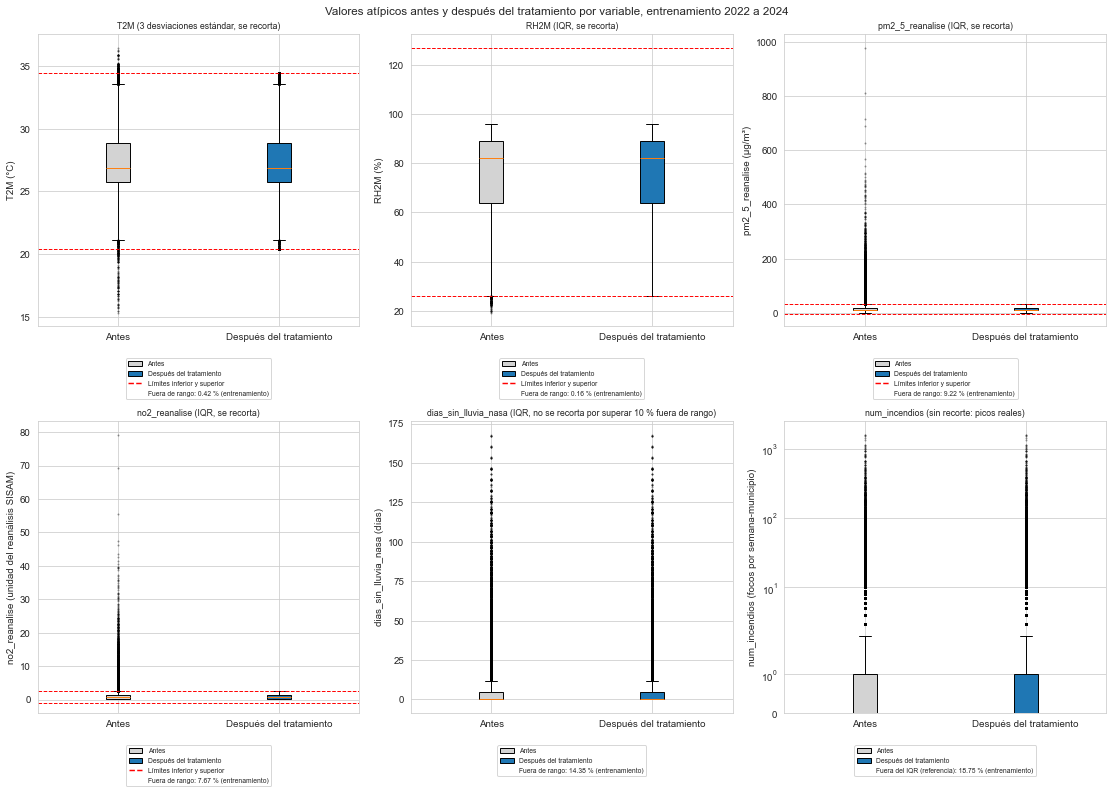

In [14]:
PANELES_ATIPICOS = [
    ("T2M", "°C"), ("RH2M", "%"), ("pm2_5_reanalise", "µg/m³"),
    ("no2_reanalise", "unidad del reanálisis SISAM"), ("dias_sin_lluvia_nasa", "días"), ("num_incendios", "focos por semana-municipio"),
]
pct_fuera_num_incendios = pct_fuera(df.loc[es_ent, "num_incendios"], limites_atipicos(df.loc[es_ent, "num_incendios"], "IQR"))

fig, ejes = plt.subplots(2, 3, figsize=(16, 11.5))
for eje, (variable, unidad) in zip(ejes.ravel(), PANELES_ATIPICOS):
    despues = df.loc[es_ent, variable]
    if variable == "num_incendios":
        titulo, pct, recorta = "num_incendios (sin recorte: picos reales)", pct_fuera_num_incendios, False
    else:
        recorta = LIMITES[variable]["recortar"]
        estado = "se recorta" if recorta else "no se recorta por superar 10 % fuera de rango"
        titulo, pct = f"{variable} ({LIMITES[variable]['criterio']}, {estado})", tabla_atipicos.loc[variable, "pct_fuera_entrenamiento"]
    caja = eje.boxplot([antes[variable], despues], tick_labels=["Antes", "Después del tratamiento"], showfliers=True, patch_artist=True,
                       flierprops={"marker": ".", "markersize": 2, "alpha": 0.4})
    for parche, color in zip(caja["boxes"], ["lightgray", "tab:blue"]):
        parche.set_facecolor(color)
    manijas = [Patch(facecolor="lightgray", edgecolor="k", label="Antes"), Patch(facecolor="tab:blue", edgecolor="k", label="Después del tratamiento")]
    if recorta:
        for limite in (LIMITES[variable]["inferior"], LIMITES[variable]["superior"]):
            eje.axhline(limite, color="red", linestyle="--", linewidth=1)
        manijas.append(Line2D([0], [0], color="red", linestyle="--", label="Límites inferior y superior"))
    etiqueta_pct = "Fuera del IQR (referencia)" if variable == "num_incendios" else "Fuera de rango"
    manijas.append(Line2D([0], [0], color="none", label=f"{etiqueta_pct}: {pct:.2f} % (entrenamiento)"))
    if variable == "num_incendios":
        eje.set_yscale("symlog")
        eje.set_ylim(bottom=0)
    eje.set_title(titulo, fontsize=9)
    eje.set_ylabel(f"{variable} ({unidad})")
    eje.legend(handles=manijas, fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.1))
fig.suptitle("Valores atípicos antes y después del tratamiento por variable, entrenamiento 2022 a 2024")
plt.tight_layout()
plt.show()


**Figura 2.** Boxplots de seis variables antes y después del tratamiento de atípicos, con los valores atípicos visibles y los límites del criterio en rojo (solo donde se recorta). `dias_sin_lluvia_nasa` y `num_incendios` no se recortan. Subconjunto: entrenamiento 2022 a 2024.


### Hallazgos de esta etapa

**Qué se observa**
- Los nulos de BDQueimadas son estructurales y no se imputan. Por ejemplo, `riesgo_fuego_promedio` tiene **20,011**, **19,057**, **19,287**, **21,587** y **18,035** nulos (2022 a 2026). Solo `riesgo_fuego_t` se imputa, con la mediana del entrenamiento (**0.440**), y queda con **0** nulos; `sin_riesgo_t` conserva el dato original.
- Semanas con focos y sin riesgo en la semana actual: **93**, **105**, **96**, **325** y **227** (2022 a 2026), de **8,318**, **9,284**, **9,588**, **6,974** y **4,998** semanas con focos.
- Filas válidas: en el entrenamiento, el Frente 1 tiene **80,907** y el Frente 2 **26,027**; **54,880** filas del entrenamiento quedan fuera del Frente 2 por no tener riesgo en la semana siguiente. En prueba son **27,693** y **6,601**, y en 2026 **22,263** (`y_7d`), **20,634** (`y_30d`) y **4,635**.
- Atípicos (ver Figura 2, boxplots antes y después del tratamiento): se recortan **11** variables base y **3** no, porque superan **10 %** fuera de rango en el entrenamiento: `dias_sin_lluvia_nasa` (**14.38 %**), `co_reanalise` (**10.12 %**) y `pm10_reanalise` (**10.06 %**). En total se recortan **59,713** valores (**38,969** en entrenamiento, **6,932** en prueba y **13,812** en 2026).

**Por qué se decidió así**
- Las filas sin rezagos o sin target se marcan con banderas en lugar de borrarse, para conservar la trazabilidad de cada partición.
- Con más de 10 % fuera de rango, el IQR queda demasiado estrecho por la estacionalidad: recortar eliminaría variación real, así que solo se transforma.
- No se recortan los targets, `num_incendios`, `frp_total` ni sus rezagos, porque los picos son reales.

**Qué implica para el modelado**
- El Frente 2 solo dispone de las filas cuya semana siguiente tiene riesgo calculado.
- **Limitación:** el recorte muestra un desplazamiento de SISAM: `no2_reanalise` tiene **7,296** valores recortados en 2026, frente a **816** en la prueba.


## 3. Data Transformation

### 3.1 Transformación `log1p`
El EDA mostró que los focos, `frp_total`, `WS2M`, `precip_nasa_sem`, `dias_sin_lluvia_nasa` y los contaminantes de SISAM tienen una asimetría muy alta. Se evalúa cada candidata con la **asimetría del entrenamiento** (ya con los atípicos tratados) y se aplica `log1p` a las que tienen |asimetría| mayor que 1. **No se aplica** a `T2M`, `T2M_MAX`, `RH2M` ni a los acumulados de lluvia (ni a sus rezagos). Los targets `y_7d` y `y_30d` se entrenan con su versión `log1p`; las métricas de error de regresión se reportan después de `expm1`, en focos reales.


In [15]:
CAND_LOG1P = (["num_incendios"] + COLS_REZ_FOCOS + ["num_incendios_mm4", "frp_total", "WS2M", "precip_nasa_sem", "dias_sin_lluvia_nasa"]
              + [f"{v}_rez{k}" for v in ["precip_nasa_sem", "dias_sin_lluvia_nasa"] for k in REZAGOS] + COLS_SISAM)
asim_antes = pd.Series({c: stats.skew(df.loc[es_ent, c].dropna()) for c in CAND_LOG1P})
VARS_LOG1P = [c for c in CAND_LOG1P if abs(asim_antes[c]) > 1]
sin_log1p = [c for c in CAND_LOG1P if c not in VARS_LOG1P]

for c in VARS_LOG1P:
    assert (df[c].dropna() >= 0).all(), f"{c} tiene valores negativos: no admite log1p"
    df[c] = np.log1p(df[c])
asim_despues = pd.Series({c: stats.skew(df.loc[es_ent, c].dropna()) for c in CAND_LOG1P})

tabla_asimetria = pd.DataFrame({"asimetria_antes": asim_antes, "asimetria_despues": asim_despues,
                                "decision": ["log1p" if c in VARS_LOG1P else "sin log1p (|asimetría| <= 1)" for c in CAND_LOG1P]})
print("Asimetría del entrenamiento antes y después de log1p (solo las candidatas):")
print(tabla_asimetria.to_string(float_format=lambda v: f"{v:,.3f}"))
print(f"\nVariables con log1p ({len(VARS_LOG1P)}):", VARS_LOG1P)
print(f"Candidatas sin log1p ({len(sin_log1p)}):", sin_log1p)
PARAMS["log1p"] = {"variables": VARS_LOG1P, "umbral_asimetria": 1.0}


Asimetría del entrenamiento antes y después de log1p (solo las candidatas):
                           asimetria_antes  asimetria_despues                      decision
num_incendios                       24.367              2.126                         log1p
num_incendios_rez1                  24.371              2.138                         log1p
num_incendios_rez2                  24.456              2.152                         log1p
num_incendios_rez3                  24.557              2.168                         log1p
num_incendios_rez4                  24.572              2.184                         log1p
num_incendios_mm4                   20.399              1.999                         log1p
frp_total                           29.836              1.360                         log1p
WS2M                                 1.199              0.793                         log1p
precip_nasa_sem                      1.089             -0.498                         log1p
dias

### 3.2 Estandarización (`StandardScaler`)
Se ajusta **solo con el entrenamiento** sobre las predictoras continuas ya transformadas (focos, NASA POWER, SISAM, `lat`, `lon` y el calendario cíclico) y `riesgo_fuego_t`. **No** se aplica a banderas, columnas one-hot ni targets. Las medias y desviaciones se guardan en el JSON de parámetros.


In [16]:
COLS_CONT = (["num_incendios"] + COLS_REZ_FOCOS + ["num_incendios_mm4", "frp_total"] + COLS_NASA_ACTUAL + COLS_REZ_NASA + COLS_SISAM
             + ["lat", "lon", "sem_anio_sin", "sem_anio_cos"])
COLS_ESCALAR = COLS_CONT + ["riesgo_fuego_t"]
assert len(COLS_CONT) == len(set(COLS_CONT))
assert df.loc[es_ent, COLS_ESCALAR].notna().all().all(), "El entrenamiento no debe tener nulos en las predictoras"

pre_escala = df.loc[es_ent, COLS_ESCALAR].copy()
escalador = StandardScaler().fit(pre_escala)
df[COLS_ESCALAR] = escalador.transform(df[COLS_ESCALAR])
PARAMS["escalador"] = {"columnas": COLS_ESCALAR, "media": dict(zip(COLS_ESCALAR, map(float, escalador.mean_))),
                       "desviacion": dict(zip(COLS_ESCALAR, map(float, escalador.scale_)))}

print(f"Escalador ajustado con {len(pre_escala):,} filas de entrenamiento y {len(COLS_ESCALAR)} columnas.")
print("Entrenamiento tras escalar: media máxima en valor absoluto =", f"{df.loc[es_ent, COLS_ESCALAR].mean().abs().max():.2e}",
      "| desviación mínima y máxima =", f"{df.loc[es_ent, COLS_ESCALAR].std(ddof=0).min():.3f} y {df.loc[es_ent, COLS_ESCALAR].std(ddof=0).max():.3f}")
print("Prueba tras escalar (no tiene por qué ser 0 y 1): media de la media =", f"{df.loc[es_prueba, COLS_ESCALAR].mean().mean():.3f}",
      "| desviación promedio =", f"{df.loc[es_prueba, COLS_ESCALAR].std(ddof=0).mean():.3f}")


Escalador ajustado con 80,907 filas de entrenamiento y 50 columnas.
Entrenamiento tras escalar: media máxima en valor absoluto = 2.77e-15 | desviación mínima y máxima = 1.000 y 1.000


Prueba tras escalar (no tiene por qué ser 0 y 1): media de la media = -0.067 | desviación promedio = 0.893


### 3.3 Codificación y 3.4 Targets
- `uf` con one-hot (9 columnas), `clase_t1` ordinal de 0 a 3 (`clase_t1_ord`, junto al nombre `clase_t1`), `lat` y `lon` numéricas estandarizadas. `municipio_norm` es solo identificador y no es predictora.
- `y_7d` y `y_30d` se entrenan con `y_7d_log` e `y_30d_log`; el error se reporta después de `expm1`. El Frente 2 no se transforma.

### 3.5 Sin SMOTE aquí
**SMOTE se aplica en Modelado, solo dentro del entrenamiento de cada pliego**, nunca en validación, prueba ni 2026.


In [17]:
dummies_uf = pd.get_dummies(df["uf"], prefix="uf", dtype="int8")
COLS_UF = list(dummies_uf.columns)
assert len(COLS_UF) == 9, "Debe haber 9 columnas one-hot de uf"
df = pd.concat([df, dummies_uf], axis=1)
print("Columnas one-hot de uf:", COLS_UF)

print("\nClase de riesgo de la semana siguiente (ordinal 0 a 3), solo filas con valido_f2:")
print(pd.crosstab(df.loc[df["valido_f2"], "clase_t1_ord"], df.loc[df["valido_f2"], "clase_t1"]).to_string())
print("\nRelación entre y_7d_log y y_7d (se revierte con expm1):",
      bool(np.allclose(np.expm1(df["y_7d_log"].dropna()), df["y_7d"].dropna())))


Columnas one-hot de uf: ['uf_AC', 'uf_AM', 'uf_AP', 'uf_MA', 'uf_MT', 'uf_PA', 'uf_RO', 'uf_RR', 'uf_TO']

Clase de riesgo de la semana siguiente (ordinal 0 a 3), solo filas con valido_f2:
clase_t1      Alto   Bajo  Crítico  Moderado
clase_t1_ord                                
0                0  16924        0         0
1                0      0        0      6423
2             6778      0        0         0
3                0      0     7790         0

Relación entre y_7d_log y y_7d (se revierte con expm1): True


### Hallazgos de esta etapa

**Qué se observa**
- `log1p` se aplica a **23** de las **24** variables candidatas. Solo `o3_reanalise` (asimetría **0.535**) queda sin transformar.
- La asimetría baja mucho en los focos y `frp_total`: `num_incendios` de **24.367** a **2.126** y `frp_total` de **29.836** a **1.360**. En `pm10_reanalise` baja de **8.548** a **1.630** y en `dias_sin_lluvia_nasa` de **3.812** a **1.158**. `co_reanalise` sigue en **4.848**.
- El `StandardScaler` se ajusta con **80,907** filas de entrenamiento y **50** columnas. En el entrenamiento la desviación queda en **1.000**; en la prueba, la desviación promedio es **0.893** y la media de las medias **-0.067**.
- `uf` genera **9** columnas one-hot y `clase_t1_ord` va de 0 a 3 sin ambigüedad con el nombre. `y_7d_log` se revierte con `expm1` (**True**).

**Por qué se decidió así**
- Se usa el umbral |asimetría| mayor que 1 medido en el entrenamiento, ya con los atípicos tratados. Varias variables lo superan por poco (`precip_nasa_sem` **1.089**, `pm2_5_reanalise` **1.042**, `no2_reanalise` **1.051**, `so2_reanalise` **1.058**): se transforman para aplicar una regla única.
- El escalador se ajusta solo con el entrenamiento, y la prueba y 2026 usan esos mismos parámetros.

**Qué implica para el modelado**
- Los modelos de regresión se entrenan con `y_7d_log` e `y_30d_log`, y el error se reporta después de `expm1`, en focos reales.
- **SMOTE no se aplica aquí:** se hará en Modelado, solo dentro del entrenamiento de cada pliego.
- **Limitación:** `co_reanalise` conserva una asimetría alta (**4.848**) incluso con `log1p`.


## 4. Data Reduction

### 4.1 VIF iterativo
Se calcula el factor de inflación de la varianza (VIF) **solo con el entrenamiento**, sobre las predictoras continuas ya transformadas y estandarizadas (no sobre one-hot ni banderas). En cada paso se elimina la variable con mayor VIF y se recalcula, hasta que todas las no protegidas queden por debajo de **10**. El VIF de cada variable es la diagonal de la inversa de la matriz de correlación.

**Variables protegidas** (no se eliminan por VIF): `num_incendios`, sus rezagos 1 a 4 y `num_incendios_mm4`, porque son la base de la persistencia. Su VIF se informa aunque sea alto. La colinealidad conocida del EDA (`pm10` con `pm2_5` 0.999, ambos con `co`, `no2` con `so2`, y `frp_total` con `num_incendios` 0.914) se deja a decisión del VIF.


In [18]:
PROTEGIDAS = ["num_incendios"] + COLS_REZ_FOCOS + ["num_incendios_mm4"]
UMBRAL_VIF = 10.0


def calcular_vif(matriz):
    # VIF de cada columna: diagonal de la inversa de la matriz de correlacion
    correlacion = np.corrcoef(matriz.to_numpy(float), rowvar=False)
    return pd.Series(np.diag(np.linalg.pinv(correlacion)), index=matriz.columns)


def vif_iterativo(matriz, protegidas, umbral=UMBRAL_VIF):
    # elimina de a una la variable no protegida con mayor VIF hasta que todas queden bajo el umbral
    actuales = list(matriz.columns)
    historial = []
    while True:
        vif = calcular_vif(matriz[actuales])
        candidatas = vif.drop(protegidas, errors="ignore")
        if candidatas.max() < umbral:
            return actuales, vif, pd.DataFrame(historial)
        peor = candidatas.idxmax()
        historial.append({"iteracion": len(historial) + 1, "eliminada": peor, "vif_eliminada": candidatas[peor],
                          "variables_restantes": len(actuales) - 1})
        actuales.remove(peor)


matriz_vif = df.loc[es_ent, COLS_CONT]
vif_inicial = calcular_vif(matriz_vif)
print(f"VIF inicial de {len(COLS_CONT)} predictoras continuas (las 15 mayores):")
mostrar(vif_inicial.sort_values(ascending=False).head(15).to_frame("vif"), 1)


VIF inicial de 49 predictoras continuas (las 15 mayores):
                      vif
precip_acum_30d_rez1 59.5
num_incendios_mm4    58.3
precip_acum_30d_rez3 51.9
precip_acum_30d_rez2 51.9
pm10_reanalise       50.1
RH2M_rez2            47.9
RH2M_rez3            46.5
RH2M_rez1            46.3
T2M_MAX_rez2         42.8
T2M_MAX_rez1         41.7
T2M_MAX_rez3         41.7
RH2M                 35.6
T2M_MAX              34.7
precip_acum_30d      34.7
RH2M_rez4            34.6


In [19]:
COLS_VIF_FINAL, vif_final, historial_vif = vif_iterativo(matriz_vif, PROTEGIDAS)
print(f"Iteraciones: {len(historial_vif)}")
mostrar(historial_vif.set_index("iteracion"), 1)
print(f"\nVariables que quedan: {len(COLS_VIF_FINAL)} de {len(COLS_CONT)}")
print("Eliminadas:", list(historial_vif["eliminada"]))


Iteraciones: 17
                      eliminada  vif_eliminada  variables_restantes
iteracion                                                          
1          precip_acum_30d_rez1           59.5                   48
2          precip_acum_30d_rez3           51.9                   47
3                pm10_reanalise           50.1                   46
4                     RH2M_rez2           47.9                   45
5                  T2M_MAX_rez1           41.4                   44
6                     RH2M_rez3           40.7                   43
7                  T2M_MAX_rez3           35.4                   42
8                     RH2M_rez1           33.0                   41
9                  T2M_MAX_rez2           27.7                   40
10         precip_acum_30d_rez2           23.1                   39
11                      T2M_MAX           22.1                   38
12                    RH2M_rez4           17.1                   37
13                    frp_total 

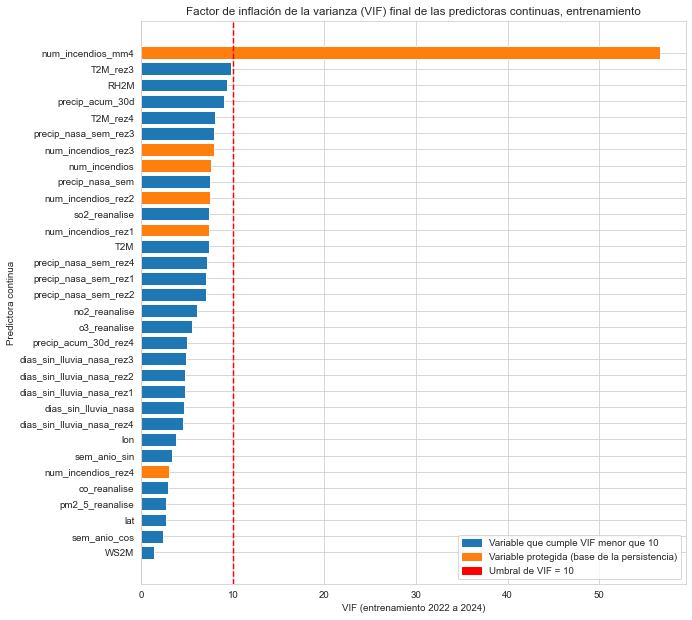

VIF final de todas las variables que quedan (de mayor a menor):
                           vif
num_incendios_mm4         56.7
T2M_rez3                   9.7
RH2M                       9.3
precip_acum_30d            9.1
T2M_rez4                   8.1
precip_nasa_sem_rez3       8.0
num_incendios_rez3         7.9
num_incendios              7.6
precip_nasa_sem            7.5
num_incendios_rez2         7.5
so2_reanalise              7.4
num_incendios_rez1         7.4
T2M                        7.4
precip_nasa_sem_rez4       7.1
precip_nasa_sem_rez1       7.1
precip_nasa_sem_rez2       7.0
no2_reanalise              6.1
o3_reanalise               5.5
precip_acum_30d_rez4       5.0
dias_sin_lluvia_nasa_rez3  4.9
dias_sin_lluvia_nasa_rez2  4.8
dias_sin_lluvia_nasa_rez1  4.8
dias_sin_lluvia_nasa       4.7
dias_sin_lluvia_nasa_rez4  4.5
lon                        3.8
sem_anio_sin               3.3
num_incendios_rez4         3.0
co_reanalise               2.9
pm2_5_reanalise            2.7
lat   

In [20]:
vif_ordenado = vif_final.sort_values()
colores = ["tab:orange" if v in PROTEGIDAS else "tab:blue" for v in vif_ordenado.index]
fig, ax = plt.subplots(figsize=(10, max(5, 0.28 * len(vif_ordenado))))
ax.barh(vif_ordenado.index, vif_ordenado.values, color=colores)
ax.axvline(UMBRAL_VIF, color="red", linestyle="--")
ax.set_xlabel("VIF (entrenamiento 2022 a 2024)")
ax.set_ylabel("Predictora continua")
ax.set_title("Factor de inflación de la varianza (VIF) final de las predictoras continuas, entrenamiento")
ax.legend(handles=[Patch(color="tab:blue", label="Variable que cumple VIF menor que 10"),
                   Patch(color="tab:orange", label="Variable protegida (base de la persistencia)"),
                   Patch(color="red", label="Umbral de VIF = 10")], loc="lower right")
plt.tight_layout()
plt.show()
print("VIF final de todas las variables que quedan (de mayor a menor):")
mostrar(vif_final.sort_values(ascending=False).to_frame("vif"), 1)
print(f"\nMayor VIF entre las no protegidas: {vif_final.drop(PROTEGIDAS).max():.1f}")


**Figura 3.** VIF de las predictoras continuas que quedan después del procedimiento iterativo, con el umbral de 10. Las variables protegidas aparecen en otro color. Subconjunto: entrenamiento.


### 4.2 Listas de features para la ablación
Se arman dos listas por frente: **con SISAM** (resultado del VIF más calendario y ubicación) y **sin SISAM** (la misma lista sin las variables de calidad del aire). El Frente 2 agrega `riesgo_fuego_t` y `sin_riesgo_t`. Los modelos de árboles no necesitan VIF; las listas se usan por consistencia. Se guardan en `lista_features.json`.


In [21]:
BASE_FEATURES = COLS_VIF_FINAL + ["temporada_seca"] + COLS_UF
FEATURES = {
    "frente1_con_sisam": BASE_FEATURES,
    "frente1_sin_sisam": [c for c in BASE_FEATURES if c not in COLS_SISAM],
    "frente2_con_sisam": BASE_FEATURES + ["riesgo_fuego_t", "sin_riesgo_t"],
    "frente2_sin_sisam": [c for c in BASE_FEATURES if c not in COLS_SISAM] + ["riesgo_fuego_t", "sin_riesgo_t"],
}
quitadas_sisam = [c for c in COLS_SISAM if c in COLS_VIF_FINAL]
print("Variables de SISAM que sobreviven al VIF:", quitadas_sisam)
for nombre, lista in FEATURES.items():
    assert len(lista) == len(set(lista)) and all(c in df.columns for c in lista), nombre
    print(f"{nombre}: {len(lista)} features")
print("\nfrente1_con_sisam:", FEATURES["frente1_con_sisam"])


Variables de SISAM que sobreviven al VIF: ['pm2_5_reanalise', 'o3_reanalise', 'no2_reanalise', 'co_reanalise', 'so2_reanalise']
frente1_con_sisam: 42 features
frente1_sin_sisam: 37 features
frente2_con_sisam: 44 features
frente2_sin_sisam: 39 features

frente1_con_sisam: ['num_incendios', 'num_incendios_rez1', 'num_incendios_rez2', 'num_incendios_rez3', 'num_incendios_rez4', 'num_incendios_mm4', 'T2M', 'RH2M', 'WS2M', 'precip_nasa_sem', 'dias_sin_lluvia_nasa', 'precip_acum_30d', 'precip_acum_30d_rez4', 'dias_sin_lluvia_nasa_rez1', 'dias_sin_lluvia_nasa_rez2', 'dias_sin_lluvia_nasa_rez3', 'dias_sin_lluvia_nasa_rez4', 'T2M_rez3', 'T2M_rez4', 'precip_nasa_sem_rez1', 'precip_nasa_sem_rez2', 'precip_nasa_sem_rez3', 'precip_nasa_sem_rez4', 'pm2_5_reanalise', 'o3_reanalise', 'no2_reanalise', 'co_reanalise', 'so2_reanalise', 'lat', 'lon', 'sem_anio_sin', 'sem_anio_cos', 'temporada_seca', 'uf_AC', 'uf_AM', 'uf_AP', 'uf_MA', 'uf_MT', 'uf_PA', 'uf_RO', 'uf_RR', 'uf_TO']


### Hallazgos de esta etapa

**Qué se observa**
- El VIF inicial de las **49** predictoras continuas llega a **59.5** (`precip_acum_30d_rez1`), **58.3** (`num_incendios_mm4`), **50.1** (`pm10_reanalise`) y **47.9** (`RH2M_rez2`).
- Tras **17** iteraciones quedan **32** variables, todas las no protegidas con VIF menor que 10 (el mayor es **9.7**, ver Figura 3). Se eliminaron los rezagos 1 a 3 de la lluvia acumulada (`precip_acum_30d`), los rezagos de `RH2M` (1 a 4) y de `T2M_MAX` (1 a 4), `T2M_MAX`, `T2M_rez1`, `T2M_rez2`, `precip_acum_120d`, `frp_total` y `pm10_reanalise`.
- Las variables protegidas quedan con VIF de **7.4** a **7.9** (`num_incendios` y sus rezagos 1 a 3) y **3.0** (rezago 4). `num_incendios_mm4` tiene **56.7**.
- De SISAM sobreviven **5** de 6 variables (`pm2_5`, `o3`, `no2`, `co` y `so2`) con VIF de **2.7**, **5.5**, **6.1**, **2.9** y **7.4**.
- Las listas quedan en **42** features (Frente 1 con SISAM), **37** (sin SISAM), **44** (Frente 2 con SISAM) y **39** (sin SISAM).

**Por qué se decidió así**
- Los rezagos de una misma variable son casi la misma señal, por eso el VIF elimina varios rezagos de lluvia, humedad y temperatura máxima.
- `pm10` y `pm2_5` tienen una correlación de 0.999 en el EDA: el VIF eliminó `pm10` y conservó `pm2_5`, lo que da la misma información. `frp_total` sale por su relación con `num_incendios`, como anticipó el EDA.
- Las variables de focos están protegidas porque son la base de la persistencia.

**Qué implica para el modelado**
- La ablación compara 5 variables de SISAM con y sin ellas, y la lista del Frente 2 agrega `riesgo_fuego_t` y `sin_riesgo_t`.
- **Limitación:** `num_incendios_mm4` conserva un VIF de **56.7** por estar protegida (es un promedio de los focos actuales y sus rezagos). Es aceptable en árboles, pero en modelos lineales conviene evaluar quitarla.


## 5. Data Integration

### 5.1 Ensamble del dataset preparado
`dataset_panel_PREPARADO.csv` reúne en una sola tabla: las claves, la partición y el pliego de validación, las banderas de validez, los targets (originales y `log1p`, `clase_t1` ordinal y en texto, `clase_t`), el nivel de focos, las columnas de contexto para el KPI y el dashboard (sin transformar) y todas las features finales transformadas.


In [22]:
COLS_CLAVES = ["semana", "municipio_norm", "uf", "particion", "pliego_validacion", "valido_f1", "valido_f1_30d", "valido_f2"]
COLS_TARGETS = ["y_7d", "y_30d", "y_7d_log", "y_30d_log", "clase_t1_ord", "clase_t1", "clase_t", "nivel_focos"]
COLS_CONTEXTO = ["deter_num_alertas", "deter_area_ha", "deter_num_alertas_area_protegida", "fuente_sisam",
                 "ctx_pm2_5_reanalise", "ctx_pm10_reanalise", "num_incendios_crudo", "lat_grados", "lon_grados"]
COLS_FEATURES_FINALES = list(dict.fromkeys(FEATURES["frente2_con_sisam"]))
COLUMNAS_FINALES = COLS_CLAVES + COLS_TARGETS + COLS_CONTEXTO + [c for c in COLS_FEATURES_FINALES if c not in COLS_CLAVES + COLS_TARGETS + COLS_CONTEXTO]

final = df[COLUMNAS_FINALES].copy()
for c in ["valido_f1", "valido_f1_30d", "valido_f2"]:
    final[c] = final[c].astype("int8")
for c in final.select_dtypes("float64").columns:
    final[c] = final[c].astype("float32")
final["semana"] = final["semana"].dt.strftime("%Y-%m-%d")

RUTA_SALIDA = DIR_PREPARATION / "dataset_panel_PREPARADO.csv"
final.to_csv(RUTA_SALIDA, index=False, encoding="utf-8", float_format="%.6g")
print("Guardado:", RUTA_SALIDA.relative_to(BASE), final.shape, f"({RUTA_SALIDA.stat().st_size / 1e6:,.1f} MB)")
print("Columnas:", len(COLUMNAS_FINALES), "| claves:", len(COLS_CLAVES), "| targets:", len(COLS_TARGETS), "| contexto:", len(COLS_CONTEXTO),
      "| features:", len(COLS_FEATURES_FINALES))


Guardado: datos\datasets_preparation\dataset_panel_PREPARADO.csv (136293, 69) (62.1 MB)
Columnas: 69 | claves: 8 | targets: 8 | contexto: 9 | features: 44


### 5.2 Archivos auxiliares
- `parametros_preparacion.json`: fechas de particiones y pliegos, límites de atípicos, variables con `log1p`, medias y desviaciones del escalador, mediana de imputación, percentiles de KPI, umbrales de clase y regla de la fila válida.
- `lista_features.json`: las cuatro listas de features (`frente1_con_sisam`, `frente1_sin_sisam`, `frente2_con_sisam`, `frente2_sin_sisam`).
- `kpi_parametros.json`: parámetros fijos del KPI aprobados por el equipo, cada uno con su fuente.


In [23]:
PARAMS["umbrales_clase_riesgo"] = {"cortes": [0.40, 0.70, 0.95], "clases": CLASES, "ordinal": ORDINAL_CLASE,
                                   "regla": "Bajo <= 0.40; Moderado (0.40, 0.70]; Alto (0.70, 0.95]; Crítico > 0.95; solo t+1"}
PARAMS["regla_fila_valida"] = {
    "valido_f1": "rezagos y media móvil completos y y_7d no nulo",
    "valido_f1_30d": "valido_f1 y y_30d no nulo (suma de las 4 semanas siguientes con min_count=4)",
    "valido_f2": "rezagos completos y clase_t1 no nula (riesgo calculado en la semana siguiente)"}
PARAMS["vif"] = {"umbral": UMBRAL_VIF, "protegidas": PROTEGIDAS, "eliminadas": list(historial_vif["eliminada"]),
                 "finales": {c: float(v) for c, v in vif_final.items()}}
PARAMS["limitacion"] = "Los parámetros se ajustan con todo el entrenamiento y no pliego por pliego."

KPI = {
    "nivel_focos_municipio_semana": {"valor": {"cortes_por_temporada": PARAMS["kpi_cortes_focos"], "seca": "julio a noviembre",
                                              "niveles": ["Sin focos", "Habitual (hasta p50)", "Elevado (hasta p75)", "Muy elevado (más de p75)"]},
                                    "fuente": "Calculado con las semanas con focos del entrenamiento (2022 a 2024); EDA sección 14"},
    "alerta": {"valor": "nivel Muy elevado", "fuente": "Decisión del equipo; con Elevado o Muy elevado la capacidad de 70 se supera en 86 % de las semanas secas"},
    "capacidad_de_atencion_municipios_en_alerta": {"valor": {"base": 70, "sensibilidad": [60, 150]},
                                                    "fuente": "Supuesto derivado de 1,489 brigadistas y brigadas de 10 a 25; no existe dato oficial"},
    "variacion_interanual_de_focos": {"valor": {"referencia_pct": 40, "por": "estado y mes"}, "fuente": "Pará 2024: +50 % en julio y +40 % en agosto"},
    "anticipacion_minima": {"valor": {"dias": 3}, "fuente": "Ataque inicial medio 25.6 h nacional y 55 h en el Norte; Ramalho et al. 2021 (supuesto declarado: con datos semanales no se mide)"},
    "punto_de_operacion": {"valor": {"regla": "probabilidad > C/L", "C_sobre_L": [0.1, 0.2, 0.5]}, "fuente": "Regla costo-pérdida; sin valores públicos"},
    "kpis_de_control": {"valor": ["recall de alerta", "falsas alarmas", "MAE móvil de 4 semanas"], "fuente": "Los umbrales se fijan tras el modelado con datos de validación"},
    "referencias_de_contexto": {"valor": {"riesgo_fuego_inpe": [0.15, 0.40, 0.70, 0.95], "pm2_5_oms_ug_m3": 15, "pm2_5_conama_pi1_ug_m3": 60},
                                "fuente": "Solo contexto en el dashboard"},
}

for nombre, contenido in [("parametros_preparacion.json", PARAMS), ("lista_features.json", FEATURES), ("kpi_parametros.json", KPI)]:
    ruta = DIR_PREPARATION / nombre
    with open(ruta, "w", encoding="utf-8") as archivo:
        json.dump(contenido, archivo, ensure_ascii=False, indent=2)
    print(f"Guardado: {ruta.relative_to(BASE)} ({ruta.stat().st_size / 1e3:,.1f} KB)")


Guardado: datos\datasets_preparation\parametros_preparacion.json (13.2 KB)
Guardado: datos\datasets_preparation\lista_features.json (3.6 KB)
Guardado: datos\datasets_preparation\kpi_parametros.json (2.1 KB)


### 5.3 Verificaciones finales
Todas las verificaciones son `assert` y quedan impresas. Incluyen la prueba de fuga: se alteran todos los datos posteriores a una fecha, se vuelven a construir las variables y se comprueba que las features de las semanas anteriores no cambian.


In [24]:
RECARGA = pd.read_csv(RUTA_SALIDA, parse_dates=["semana"])

# 1. claves y forma
assert not RECARGA.duplicated(CLAVE + ["semana"]).any()
assert len(RECARGA) == 543 * 251
print(f"OK 1: sin claves duplicadas; filas = {len(RECARGA):,} = 543 x 251")

# 2. particiones sin solapamiento y con margen de 4 semanas
rango = RECARGA.groupby("particion")["semana"].agg(["min", "max"])
assert rango.loc["entrenamiento", "max"] == ENT_FIN and rango.loc["entrenamiento", "min"] == ENT_INI
assert rango.loc["margen", "min"] - rango.loc["entrenamiento", "max"] == pd.Timedelta(weeks=1)
assert rango.loc["prueba", "min"] - rango.loc["entrenamiento", "max"] == pd.Timedelta(weeks=SEMANAS_MARGEN + 1)
assert rango.loc["prueba", "min"] > rango.loc["margen", "max"] and rango.loc["flujo_2026", "min"] > rango.loc["prueba", "max"]
print("OK 2: particiones sin solapamiento y con margen de 4 semanas entre entrenamiento y prueba")

# 3. ninguna fila posterior a 2024-12-02 es de entrenamiento y viceversa
assert (RECARGA.loc[RECARGA["particion"] == "entrenamiento", "semana"] <= ENT_FIN).all()
assert (RECARGA.loc[RECARGA["particion"].isin(["margen", "prueba", "flujo_2026"]), "semana"] > ENT_FIN).all()
print("OK 3: entrenamiento solo hasta 2024-12-02; margen, prueba y 2026 solo después")

# 4. pliegos
for p in PLIEGOS:
    assert df.loc[p["idx_entreno"], "semana"].max() + pd.Timedelta(weeks=SEMANAS_MARGEN) < df.loc[p["idx_validacion"], "semana"].min()
    assert df.loc[p["idx_validacion"], "particion"].eq("entrenamiento").all()
print("OK 4: en cada pliego, máximo del entrenamiento + 4 semanas < inicio de la validación")

# 5. el escalador se calculo solo con entrenamiento
for c in COLS_ESCALAR:
    assert np.isclose(pre_escala[c].mean(), PARAMS["escalador"]["media"][c]) and np.isclose(pre_escala[c].std(ddof=0), PARAMS["escalador"]["desviacion"][c])
assert np.allclose(df.loc[es_ent, COLS_ESCALAR].mean(), 0, atol=1e-6)
print("OK 5: medias y desviaciones del escalador recalculadas con entrenamiento y coinciden con el JSON")


OK 1: sin claves duplicadas; filas = 136,293 = 543 x 251
OK 2: particiones sin solapamiento y con margen de 4 semanas entre entrenamiento y prueba
OK 3: entrenamiento solo hasta 2024-12-02; margen, prueba y 2026 solo después
OK 4: en cada pliego, máximo del entrenamiento + 4 semanas < inicio de la validación
OK 5: medias y desviaciones del escalador recalculadas con entrenamiento y coinciden con el JSON


In [25]:
# 6. prueba de fuga: se alteran los datos posteriores a t0 y las features de las semanas anteriores no deben cambiar
base_original = pd.read_csv(RUTA_PANEL, parse_dates=["semana"]).sort_values(CLAVE + ["semana"]).reset_index(drop=True)
T0 = pd.Timestamp("2024-06-03")
alterado = base_original.copy()
posterior = alterado["semana"] > T0
rng = np.random.default_rng(ALEATORIO)
for c in ["num_incendios", "riesgo_fuego_promedio"] + COLS_NASA_ACTUAL + COLS_SISAM:
    alterado[c] = alterado[c].astype(float)
    alterado.loc[posterior, c] = rng.uniform(0, 100, posterior.sum())
original_construido = construir_variables(base_original)
alterado_construido = construir_variables(alterado)

FEATURES_SIN_FUTURO = COLS_REZ_FOCOS + ["num_incendios_mm4"] + COLS_REZ_NASA + ["riesgo_fuego_t", "sin_riesgo_t", "temporada_seca",
                                                                                 "sem_anio_sin", "sem_anio_cos", "num_incendios"] + COLS_NASA_ACTUAL + COLS_SISAM
antes_de_t0 = (original_construido["semana"] <= T0).to_numpy()
for c in FEATURES_SIN_FUTURO:
    a = original_construido.loc[antes_de_t0, c].to_numpy(float)
    b = alterado_construido.loc[antes_de_t0, c].to_numpy(float)
    assert np.allclose(a, b, equal_nan=True), f"La feature {c} cambia al alterar datos posteriores a t: usa información del futuro"
print(f"OK 6: {len(FEATURES_SIN_FUTURO)} features no cambian al alterar todos los datos posteriores a {T0.date()} (sin fuga hacia el pasado)")
verificar_a_mano(base_original.pipe(construir_variables))
print("OK 6b: rezagos, media móvil y targets recalculados a mano para 3 municipios")

# 7. sin nulos en las features finales dentro de las filas validas
for frente, bandera, lista in [("Frente 1", "valido_f1", FEATURES["frente1_con_sisam"]), ("Frente 2", "valido_f2", FEATURES["frente2_con_sisam"])]:
    filas_validas = RECARGA[RECARGA[bandera] == 1]
    assert filas_validas[lista].notna().all().all(), f"{frente}: hay nulos en las features de las filas válidas"
    print(f"OK 7: {frente} sin nulos en {len(lista)} features dentro de {len(filas_validas):,} filas válidas")


OK 6: 49 features no cambian al alterar todos los datos posteriores a 2024-06-03 (sin fuga hacia el pasado)


OK 6b: rezagos, media móvil y targets recalculados a mano para 3 municipios
OK 7: Frente 1 sin nulos en 42 features dentro de 133,578 filas válidas
OK 7: Frente 2 sin nulos en 44 features dentro de 37,915 filas válidas


### 5.4 Qué entra al modelado
Filas por partición y por frente, número de columnas de cada lista de features y la distribución de `clase_t1` por partición (para el informe, incluido el desplazamiento de 2025).


In [26]:
orden_particion = ["entrenamiento", "margen", "prueba", "flujo_2026", "descartada"]
tabla_modelado = RECARGA.groupby("particion").agg(filas=("semana", "size"), frente1_y7d=("valido_f1", "sum"),
                                                  frente1_y30d=("valido_f1_30d", "sum"), frente2=("valido_f2", "sum")).loc[orden_particion]
print("Filas por partición y frente:")
mostrar(tabla_modelado, 0)
print("\nColumnas de features por lista:", {k: len(v) for k, v in FEATURES.items()})

dist_clase = pd.crosstab(RECARGA.loc[RECARGA["valido_f2"] == 1, "particion"], RECARGA.loc[RECARGA["valido_f2"] == 1, "clase_t1"])[CLASES]
print("\nDistribución de clase_t1 por partición (conteo, filas con valido_f2):")
mostrar(dist_clase.loc[["entrenamiento", "prueba", "flujo_2026"]], 0)
print("\nPorcentaje por partición:")
mostrar(dist_clase.div(dist_clase.sum(axis=1), axis=0).loc[["entrenamiento", "prueba", "flujo_2026"]] * 100, 1)

print("\nFocos de los targets del Frente 1 (media de y_7d y porcentaje de ceros) por partición:")
f1 = RECARGA[RECARGA["valido_f1"] == 1].groupby("particion")["y_7d"].agg(media="mean", pct_ceros=lambda s: (s == 0).mean() * 100)
mostrar(f1.loc[["entrenamiento", "prueba", "flujo_2026"]], 2)


Filas por partición y frente:
               filas  frente1_y7d  frente1_y30d  frente2
particion                                               
entrenamiento  80907        80907         80907    26027
margen          2172         2172          2172      516
prueba         27693        27693         27693     6601
flujo_2026     22806        22263         20634     4635
descartada      2715          543           543      136

Columnas de features por lista: {'frente1_con_sisam': 42, 'frente1_sin_sisam': 37, 'frente2_con_sisam': 44, 'frente2_sin_sisam': 39}

Distribución de clase_t1 por partición (conteo, filas con valido_f2):
clase_t1        Bajo  Moderado  Alto  Crítico
particion                                    
entrenamiento  12512      4118  4215     5182
prueba          2742      1151  1345     1363
flujo_2026      1315      1046  1116     1158

Porcentaje por partición:
clase_t1       Bajo  Moderado  Alto  Crítico
particion                                   
entrenamiento  48.1

### Hallazgos de esta etapa

**Qué se observa**
- El dataset preparado tiene **136,293 filas x 69 columnas** (8 de claves y banderas, 8 de targets, 9 de contexto y **44** features) y pesa **62.1 MB**. Se guardaron también `parametros_preparacion.json`, `lista_features.json` y `kpi_parametros.json`.
- Pasaron todas las verificaciones: sin claves duplicadas, particiones sin solapamiento con el margen de 4 semanas, escalador calculado solo con entrenamiento, y sin nulos en las features de las filas válidas (**133,578** del Frente 1 y **37,915** del Frente 2). La prueba de fuga alteró todos los datos posteriores a 2024-06-03 y **49** features no cambiaron.
- La clase `clase_t1` cambia entre particiones: Bajo **48.1 %** (entrenamiento), **41.5 %** (prueba) y **28.4 %** (2026); Crítico **19.9 %**, **20.6 %** y **25.0 %**.
- La media de `y_7d` es **4.33** en entrenamiento, **1.57** en prueba y **1.98** en 2026, y el porcentaje de ceros sube de **67.48 %** a **74.99 %** y **78.23 %**.

**Por qué se decidió así**
- Las columnas de contexto (`deter_*`, `fuente_sisam`, PM2.5 y PM10 sin transformar, focos crudos y coordenadas en grados) se guardan sin transformar para el KPI y el dashboard.
- La prueba de fuga con datos alterados es más fuerte que revisar el código: demuestra que ninguna feature usa información posterior a `t`.

**Qué implica para el modelado**
- **Limitación:** `riesgo_fuego_promedio` lo calcula INPE a partir de clima, así que `clase_t1` es en parte función del clima. Una fuerte asociación entre clima y clase es esperable y las métricas del Frente 2 no demuestran por sí solas capacidad predictiva.
- **Limitación:** hay desplazamiento entre entrenamiento, prueba y 2026 (menos focos y otra mezcla de clases). Las métricas de la prueba y del flujo 2026 no son comparables con las de validación y se reportan por separado.
- **Limitación:** los parámetros se ajustan con todo el entrenamiento y no por pliego.


### Resumen para el informe

- **Partición:** entrenamiento del 2022-01-31 al 2024-12-02 (**80,907** filas), margen de **4 semanas**, prueba final con 2025 (**27,693** filas) y flujo simulado 2026 (**22,806** filas). La semana 2025-12-29, que mezcla fuentes de SISAM, y las 4 primeras semanas quedan descartadas.
- **Validación cruzada temporal:** **4** pliegos de ventana expansiva (validación en 2023 S1, 2023 S2, 2024 S1 y 2024 S2) con margen de 4 semanas. **Limitación:** el pliego 1 entrena con solo **44** semanas.
- **Sin fuga:** todos los parámetros se ajustan solo con el entrenamiento y se verificó con datos alterados que **49** features no cambian al modificar el futuro. **Limitación:** se ajustan con todo el entrenamiento y no por pliego.
- **Variables construidas:** targets `y_7d` e `y_30d` (con `log1p`), `clase_t1` ordinal de 0 a 3, rezagos de 1 a 4 semanas de focos y de 6 variables de NASA POWER, media móvil de 4 semanas, calendario cíclico y ubicación.
- **Limpieza:** los nulos estructurales no se imputan; `riesgo_fuego_t` se imputa con la mediana del entrenamiento (**0.440**) y se acompaña de `sin_riesgo_t`. Los atípicos se recortan con 3 desviaciones estándar o IQR en **11** variables, y no en 3 que superan **10 %** fuera de rango.
- **Transformación:** `log1p` en **23** variables con |asimetría| mayor que 1, `StandardScaler` en **50** columnas y one-hot de `uf`. Sin SMOTE aquí: se aplica en Modelado, solo dentro de cada pliego.
- **Reducción:** el VIF iterativo deja **32** de 49 predictoras continuas. Quedan **42** features (Frente 1) y **44** (Frente 2) con SISAM, y **37** y **39** sin SISAM, para la ablación.
- **KPI:** alerta = nivel Muy elevado con cortes de focos de **2** y **5** (húmeda) y **4** y **12** (seca) calculados con el entrenamiento; los demás parámetros del KPI van con su fuente en `kpi_parametros.json`.
- **Desplazamiento:** **Limitación:** la media de `y_7d` baja de **4.33** (entrenamiento) a **1.57** (prueba) y **1.98** (2026), y la clase Bajo pasa de **48.1 %** a **41.5 %** y **28.4 %**. Las métricas de prueba y 2026 se reportan por separado.
- **Frente 2:** **Limitación:** `riesgo_fuego_promedio` lo calcula INPE a partir de clima, así que `clase_t1` es en parte función del clima y una fuerte asociación no demuestra por sí sola capacidad predictiva. Solo **26,027** filas de entrenamiento pueden usarse en este frente.
